# Workshop 4

This is a Jupyter Notebook. You can add cells that contain code in Python (or other programming languages) or cells that contain text such as this one.

In [2]:
# This is a Python cell that loads data from the main file

%pip install pandas scikit-learn matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:

import pandas as pd

# Load the IMD data
IMD_df = pd.read_csv("DATA.csv")

key = "LSOA code (2021)"
lad = "Local Authority District code (2024)"
score_cols = IMD_df.columns[IMD_df.columns.str.contains("Score")]
IMD_df_scores = IMD_df[[key, lad, *score_cols]]

Benefits_df = pd.read_csv("Benefit claimants.csv", skiprows=list(range(8)) + [9],)

Benefits_df = Benefits_df.drop(columns=Benefits_df.columns[0])
Benefits_df["August 2026"] = pd.to_numeric(
    Benefits_df["August 2026"].str.replace(",", "", regex=False),
    errors="coerce",
)
Benefits_df = Benefits_df.rename(columns={
    "mnemonic": "LSOA code (2021)",
    "August 2026": "proportion benefit claimants",
})

# print(Benefits_df.head())
# print(Benefits_df.info())

Ethnicity_df = pd.read_csv("Ethnicity_data.csv", skiprows=list(range(7)) + [8],)

Ethnicity_df = Ethnicity_df.rename(columns={
    "2021 super output area - lower layer": "LSOA code (2021)",
    "Total: All usual residents": "total_residents",
    "Asian, Asian British or Asian Welsh": "asian",
    "Black, Black British, Black Welsh, Caribbean or African": "black",
    "Mixed or Multiple ethnic groups": "mixed",
    "White": "white",
    "Other ethnic group": "other_ethnic",
})

Ethnicity_df["total_residents"] = pd.to_numeric(
    Ethnicity_df["total_residents"].str.replace(",", "", regex=False),
    errors="coerce",
)
# Check NaN rows and drop 
# print(Ethnicity_df[Ethnicity_df.isna().any(axis=1)])
Ethnicity_df = Ethnicity_df.dropna(subset=["LSOA code (2021)", "total_residents"])

# Convert to proportions
group_cols = ["asian", "black", "mixed", "white", "other_ethnic"]
for c in group_cols:
    Ethnicity_df[f"{c}_prop"] = Ethnicity_df[c] / Ethnicity_df["total_residents"]

# Proportion of residents not in the White group
Ethnicity_df["minority_prop"] = 1 - Ethnicity_df["white_prop"]

# Adjust string used as key to remove description
Ethnicity_df["LSOA code (2021)"] = (
    Ethnicity_df["LSOA code (2021)"]
    .str.split(":").str[0]
    .str.strip()
)
# checks... these lines helped me look at the output. 
# Ethnicity_df["minority_prop"].describe().round(2)

# Ethnicity_df.info()

The next cell joins the data together into one large table and prints out a summary of what is in the combined table. 

In [7]:

combined_df = (
    IMD_df_scores
    .merge(Benefits_df, how="left", on="LSOA code (2021)")
    .merge(Ethnicity_df, how="left", on="LSOA code (2021)")
)

print(combined_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 33755 entries, 0 to 33754
Data columns (total 31 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   LSOA code (2021)                                                  33755 non-null  object 
 1   Local Authority District code (2024)                              33755 non-null  str    
 2   Index of Multiple Deprivation (IMD) Score                         33755 non-null  float64
 3   Income Score (rate)                                               33755 non-null  float64
 4   Employment Score (rate)                                           33755 non-null  float64
 5   Education, Skills and Training Score                              33755 non-null  float64
 6   Health Deprivation and Disability Score                           33755 non-null  float64
 7   Crime Score                               

## Task 1 - Feature Leakage. 

We are going to cluster the domains within the IMD data. The next cell of code labels the domains we will focus on. 

1. Run the code in the block below. 
2. Ask the LLM how the IMD is calculated. 
2. Ask your preferred LLM to write you some code in Python to examine how these domains are related. You could look at the correlations between each domain or whether the IMD or proportion of benefit claimants can be predicted using the domains. What data goes into the Income and Employment domains?
3. Ask your preferred LLM to cluster the domain scores using the K-means algorithm using K = 4. What are the typical features of LSOAs in each group? 
4. Add the IMD score to the domain scores and repeat the clustering with K = 4. Is this clustering "better"? How does your LLM suggest you measure better? How many of the original cluster assignments change? (Ask your LLM for the adjusted Rand index.)
5. Did the code rescale the variables? Why does it matter?


In [8]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import adjusted_rand_score

prefixes = {
    "imd": "Index of Multiple Deprivation (IMD) Score",
    "income": "Income Score",
    "employment": "Employment Score",
    "education": "Education, Skills",
    "health": "Health Deprivation",
    "crime": "Crime Score",
    "barriers": "Barriers to Housing",
    "living_env": "Living Environment Score",
}
cols = {k: next(c for c in combined_df.columns if c.startswith(v)) for k, v in prefixes.items()}

d = combined_df[list(cols.values()) + ["proportion benefit claimants"]].copy()
d = d.rename(columns={v: k for k, v in cols.items()})
d = d.rename(columns={"proportion benefit claimants": "benefits"}).dropna()

domains = ["income", "employment", "education", "health", "crime", "barriers", "living_env"]

**Claude based solution below**

Question 2 - I’ve written model_solutions.py to run after your setup code. I haven’t run it against your data, only checked that the syntax is valid, so the numbers it prints are untested.

It covers the three parts of the task:

Correlations between domains: Pearson and Spearman matrices, the strongest and weakest pairs, and a heatmap.
Predicting IMD from the domains: a linear regression on standardised scores with a 25% hold-out. A very high R² is expected because the IMD is built from these seven domains. It is a check on how the index is constructed, not a real-world finding.
Predicting benefit claimants from the domains: the same setup, plus the R² for each domain on its own. Expect Income and Employment to dominate, but note the circularity below.

What goes into the Income and Employment domains (IoD 2025):

Income measures people who depend on means-tested benefits, in or out of work. The indicators are adults and children in Income Support, income-based Jobseeker’s Allowance, income-based Employment and Support Allowance and Pension Credit (Guarantee) benefit units. The threshold is now assessed after housing costs.
Employment measures the working-age population involuntarily excluded from the labour market. It draws on claimants of Jobseeker’s Allowance (both types), New Style JSA, Employment and Support Allowance (both types), Incapacity Benefit, Severe Disablement Allowance, Carer’s Allowance, Income Support, and Universal Credit in the Preparing for work group.

Both domains are built from benefit claims, so predicting benefit claimants from them is partly circular. I put this in as a comment in the solution file so you can use it as a discussion point.

The earlier issues in your setup code still stand: df should be IMD_df on the IMD_df_scores line, and the benefits column may be a count rather than a rate.

(33716, 9)
            imd    income  employment  education    health     crime  \
count  33716.00  33716.00    33716.00   33716.00  33716.00  33716.00   
mean      21.69      0.23        0.13      21.71      0.00      0.00   
std       15.69      0.16        0.08      18.08      0.88      0.84   
min        0.16      0.00        0.00       0.00     -3.10     -3.29   
25%        9.71      0.11        0.07       7.56     -0.62     -0.60   
50%       17.47      0.18        0.11      16.57     -0.03     -0.00   
75%       29.68      0.32        0.18      31.25      0.61      0.58   
max       94.22      1.00        0.98      99.61      3.31      3.54   

       barriers  living_env  benefits  
count  33716.00    33716.00  33716.00  
mean      21.69       21.70      3.85  
std       10.23       16.11      2.75  
min        1.49        0.06      0.00  
25%       14.14        8.62      1.90  
50%       20.10       17.87      3.00  
75%       27.60       31.75      5.20  
max       63.50     

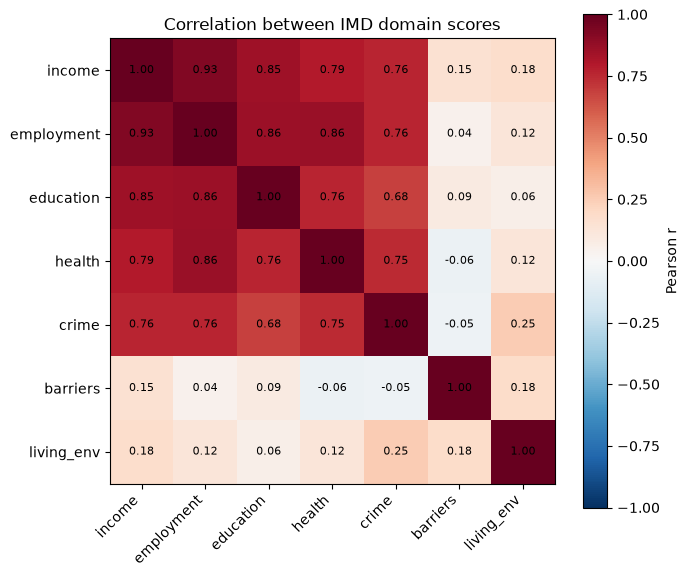


IMD ~ domains
  R^2 (train): 0.988
  R^2 (test):  0.988
employment    6.97
income        3.67
education     3.02
living_env    2.14
barriers      1.56
crime         1.14
health        0.98
Name: standardised coefficient, dtype: float64

benefits ~ domains
  R^2 (train): 0.772
  R^2 (test):  0.772
income        2.85
crime         0.31
living_env    0.31
barriers      0.04
employment   -0.11
health       -0.28
education    -0.55
Name: standardised coefficient, dtype: float64

R^2 using one domain at a time:
income        0.730
employment    0.581
crime         0.465
education     0.419
health        0.391
living_env    0.089
barriers      0.028
dtype: float64


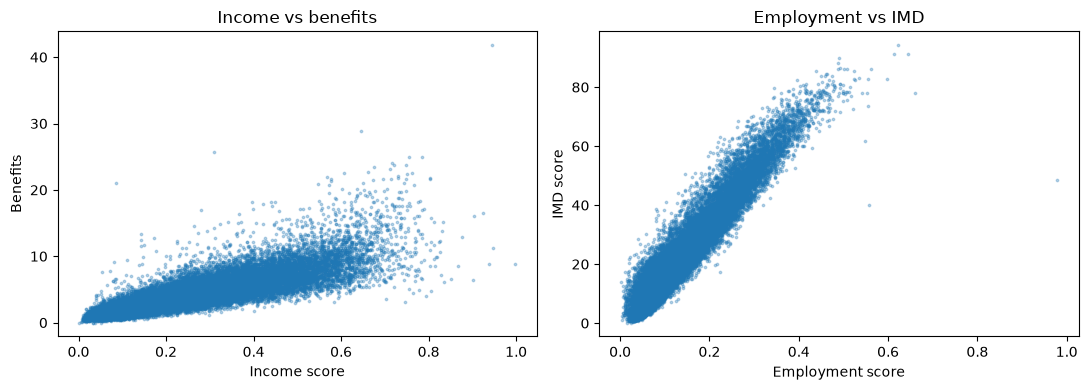

In [9]:
# Model solutions: how are the IMD domains related?
# Run this AFTER your set-up code (it uses the frame `d` and the list `domains`).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# -----------------------------------------------------------------------------
# 0. Quick look at what we are working with
# -----------------------------------------------------------------------------
# `.dropna()` in the set-up removed the LSOAs with a missing benefits value
# (39 of 33,755), so every column below has the same number of rows.
print(d.shape)
print(d.describe().round(2))


# -----------------------------------------------------------------------------
# 1. Correlations between the domains
# -----------------------------------------------------------------------------
# Pearson measures linear association; Spearman measures rank association.
# The domain scores are skewed, so it is worth checking both.
pearson = d[domains].corr(method="pearson")
spearman = d[domains].corr(method="spearman")

print("Pearson correlations\n", pearson.round(2))
print("\nSpearman correlations\n", spearman.round(2))

# Which pairs are most strongly related? Keep the upper triangle only so each
# pair appears once.
pairs = (
    pearson.where(np.triu(np.ones(pearson.shape, dtype=bool), k=1))
    .stack()
    .sort_values(ascending=False)
)
print("\nStrongest pairs:\n", pairs.head(5).round(2))
print("\nWeakest pairs:\n", pairs.tail(5).round(2))

# Heatmap
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pearson, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(domains)), domains, rotation=45, ha="right")
ax.set_yticks(range(len(domains)), domains)
for i in range(len(domains)):
    for j in range(len(domains)):
        ax.text(j, i, f"{pearson.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation between IMD domain scores")
fig.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# 2. Can the IMD score be predicted from the domains?
# -----------------------------------------------------------------------------
X = d[domains]
y = d["imd"]

# Hold out 25% of LSOAs so that we judge the model on data it has not seen.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Standardise so that coefficients are comparable (each is the change in IMD
# per one standard deviation change in that domain). Fit the scaler on the
# training data only.
scaler = StandardScaler().fit(X_train)
model_imd = LinearRegression().fit(scaler.transform(X_train), y_train)

print("\nIMD ~ domains")
print("  R^2 (train):", round(model_imd.score(scaler.transform(X_train), y_train), 3))
print("  R^2 (test): ", round(model_imd.score(scaler.transform(X_test), y_test), 3))
print(
    pd.Series(model_imd.coef_, index=domains)
    .sort_values(ascending=False)
    .round(2)
    .rename("standardised coefficient")
)

# Interpretation: R^2 is very high, which is expected because the IMD is *built*
# from these seven domains (a weighted sum, Income and Employment at 22.5% each).
# It is not exactly 1 because the IMD combines transformed domain ranks rather
# than the raw scores. The largest coefficients should be Income and Employment,
# matching their weights. This is a check on how the index is constructed,
# not a finding about the real world.


# -----------------------------------------------------------------------------
# 3. Can benefit claimants be predicted from the domains?
# -----------------------------------------------------------------------------
y_b = d["benefits"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, y_b, test_size=0.25, random_state=42
)

scaler_b = StandardScaler().fit(Xb_train)
model_ben = LinearRegression().fit(scaler_b.transform(Xb_train), yb_train)

print("\nbenefits ~ domains")
print("  R^2 (train):", round(model_ben.score(scaler_b.transform(Xb_train), yb_train), 3))
print("  R^2 (test): ", round(model_ben.score(scaler_b.transform(Xb_test), yb_test), 3))
print(
    pd.Series(model_ben.coef_, index=domains)
    .sort_values(ascending=False)
    .round(2)
    .rename("standardised coefficient")
)

# Single-domain comparison: which one domain predicts benefits best on its own?
single = {
    dom: LinearRegression().fit(d[[dom]], y_b).score(d[[dom]], y_b)
    for dom in domains
}
print("\nR^2 using one domain at a time:")
print(pd.Series(single).sort_values(ascending=False).round(3))

# Interpretation: expect Income and Employment to dominate. Be careful about
# circularity. Those two domains are themselves constructed from counts of
# people claiming (means-tested and out-of-work) benefits, so a strong
# relationship with benefit claimants is partly built in. The other domains
# (crime, living environment, barriers) add little once these are included.
# Also check what the benefits column actually measures: if it is a raw count
# rather than a rate, it will partly reflect how many people live in each LSOA.


# -----------------------------------------------------------------------------
# 4. Optional: scatter plot to see the shape of the relationship
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(d["income"], d["benefits"], s=3, alpha=0.3)
axes[0].set(xlabel="Income score", ylabel="Benefits", title="Income vs benefits")
axes[1].scatter(d["employment"], d["imd"], s=3, alpha=0.3)
axes[1].set(xlabel="Employment score", ylabel="IMD score", title="Employment vs IMD")
fig.tight_layout()
plt.show()

I have the statistical background to interpret this output. If you do not, ask further questions like "How should I interpret... correlations/the regression output/the graphs etc." or check your understanding with questions like "it looks like the domain indices are heavily related to each other is this correct?"

Question 3 - I've written `model_solutions_kmeans.py`, which runs after your setup code. I've only checked that the syntax is valid and haven't run it on your data, so I can't tell you what the four clusters look like yet.

How it works:

- **Features:** it clusters the seven domain scores only, standardised first because K-means uses Euclidean distance. It leaves out the IMD score, since that is built from the domains and would count the same information twice. It also leaves out `benefits`, which is kept back to describe the clusters.
- **Fit:** `KMeans(n_clusters=4, n_init=20, random_state=42)`. The cluster numbers are arbitrary, so the script relabels them by mean IMD (0 is least deprived, 3 is most deprived). That makes the output easier to read and reproducible.
- **Typical features of each group:** it prints cluster sizes and mean raw scores, then mean z-scores per domain, which show which domains define each group. It also shows the mean `minority_prop` per cluster, a characteristic not used in the clustering, and a heatmap of the z-score profiles.
- **Plot and stability check:** a PCA scatter coloured by cluster, and an adjusted Rand index comparing two random seeds to show the solution is stable.

I left the cluster descriptions out of the script, since they depend on what the output shows. Once you've run it, send me the profile tables and I'll write the interpretation for the model answer.

A point worth raising in the workshop is that deprivation domains form a continuum, so K-means will probably slice along it rather than find sharply separated groups. The final comment in the script notes this and suggests comparing other values of K.

Number of LSOAs per cluster:
cluster
0    12377
1     4771
2    10669
3     5899
Name: count, dtype: int64

Share of LSOAs per cluster:
cluster
0    36.7
1    14.2
2    31.6
3    17.5
Name: proportion, dtype: float64

Mean score by cluster:
         income  employment  education  health  crime  barriers  living_env  \
cluster                                                                       
0          0.10        0.07       8.41   -0.69  -0.66     17.41       13.21   
1          0.17        0.09      13.86   -0.55  -0.43     36.62       36.65   
2          0.26        0.15      24.25    0.38   0.38     19.34       22.84   
3          0.49        0.28      51.38    1.22   1.06     22.86       25.35   

           imd  benefits  
cluster                   
0         8.09      1.98  
1        18.30      3.00  
2        23.84      4.33  
3        49.09      7.61  

Mean z-score by cluster (0 = England average):
         income  employment  education  health  crime  barriers  living_en

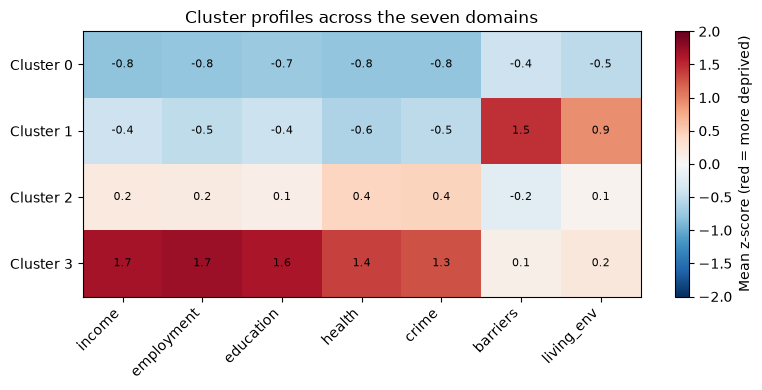


Variance explained by PC1 and PC2: [0.61 0.17]


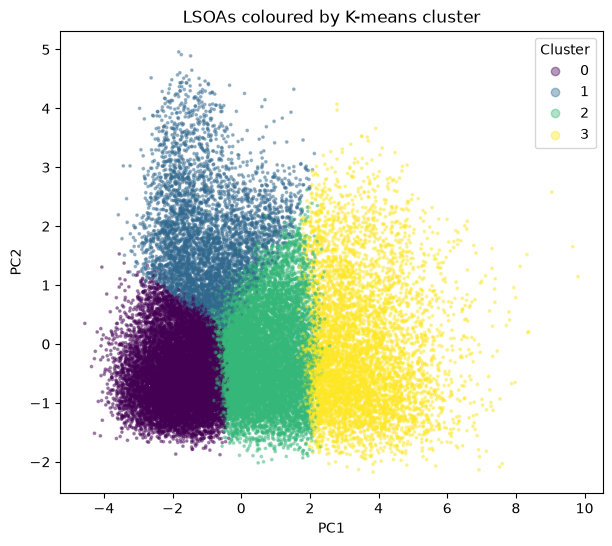


Adjusted Rand index, seed 42 vs seed 7: 0.993


In [10]:
# Model solutions: K-means clustering of the IMD domain scores (K = 4)
# Run this AFTER your set-up code (it uses `combined_df`, `d` and `domains`).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# -----------------------------------------------------------------------------
# 1. Prepare the data
# -----------------------------------------------------------------------------
# Cluster on the seven domain scores only. We leave out the overall IMD score
# (it is a combination of the domains, so it would count the same information
# twice) and the benefits column (we keep it back to help *describe* the
# clusters afterwards).
# K-means uses Euclidean distance, so put every domain on the same scale first.
# Otherwise a domain with a larger range would dominate the clustering.
X = d[domains]
X_scaled = StandardScaler().fit_transform(X)

# -----------------------------------------------------------------------------
# 2. Fit K-means with K = 4
# -----------------------------------------------------------------------------
# n_init=20 restarts the algorithm from 20 different starting points and keeps
# the best result, because K-means can get stuck in a poor local solution.
km = KMeans(n_clusters=4, n_init=20, random_state=42)
raw_labels = km.fit_predict(X_scaled)

# The label numbers are arbitrary (the algorithm could just as easily call the
# most deprived group 0 or 3). Relabel so that 0 = least deprived and
# 3 = most deprived, ordered by mean IMD score, which makes the output
# easier to read and reproducible.
order = d.groupby(raw_labels)["imd"].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
d["cluster"] = pd.Series(raw_labels, index=d.index).map(relabel)

print("Number of LSOAs per cluster:")
print(d["cluster"].value_counts().sort_index())
print("\nShare of LSOAs per cluster:")
print((d["cluster"].value_counts(normalize=True).sort_index() * 100).round(1))

# -----------------------------------------------------------------------------
# 3. What are the typical features of each cluster?
# -----------------------------------------------------------------------------
# (a) Mean raw scores. Higher = more deprived.
profile = d.groupby("cluster")[domains + ["imd", "benefits"]].mean()
print("\nMean score by cluster:")
print(profile.round(2))

# (b) The same thing as z-scores: how many standard deviations above or below
# the England-wide average is each cluster on each domain? This makes the
# domains comparable, so we can see which ones define each group.
z = pd.DataFrame(X_scaled, columns=domains, index=d.index)
z["cluster"] = d["cluster"]
z_profile = z.groupby("cluster")[domains].mean()
print("\nMean z-score by cluster (0 = England average):")
print(z_profile.round(2))

# (c) Characteristics that were NOT used to build the clusters. Do the groups
# differ on ethnicity? (`d` kept the row index from `combined_df`, so we can
# look the extra column up by index.)
d["minority_prop"] = combined_df.loc[d.index, "minority_prop"]
print("\nMean proportion of residents not in the White group, by cluster:")
print(d.groupby("cluster")["minority_prop"].mean().round(3))

# (d) Heatmap of the z-score profile: the easiest way to "read" the clusters.
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(z_profile, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(domains)), domains, rotation=45, ha="right")
ax.set_yticks(range(4), [f"Cluster {i}" for i in range(4)])
for i in range(4):
    for j in range(len(domains)):
        ax.text(j, i, f"{z_profile.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Mean z-score (red = more deprived)")
ax.set_title("Cluster profiles across the seven domains")
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 4. Picture the clusters in two dimensions
# -----------------------------------------------------------------------------
# We cannot plot seven dimensions, so project onto the first two principal
# components and colour by cluster.
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
print("\nVariance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=d["cluster"], cmap="viridis", s=3, alpha=0.4)
ax.set(xlabel="PC1", ylabel="PC2", title="LSOAs coloured by K-means cluster")
ax.legend(*sc.legend_elements(), title="Cluster")
plt.show()

# -----------------------------------------------------------------------------
# 5. How trustworthy is a K = 4 solution?
# -----------------------------------------------------------------------------
# Refit with different random starts and compare the partitions using the
# adjusted Rand index (1 = identical grouping, ~0 = no better than chance).
# Values near 1 mean the clusters are stable and not a quirk of the seed.
alt = KMeans(n_clusters=4, n_init=20, random_state=7).fit_predict(X_scaled)
print("\nAdjusted Rand index, seed 42 vs seed 7:",
      round(adjusted_rand_score(raw_labels, alt), 3))

# Note: K = 4 was chosen for us. In real work you would also compare other
# values of K, for example with the inertia ("elbow") or silhouette score, and
# remember that K-means finds groups even when the data has no clear
# cluster structure. Domain scores form a continuum of deprivation, so expect
# the groups to be slices along it rather than sharply separated clouds.

Here is a model-answer interpretation based on your output. Cluster numbers run from least to most deprived by mean IMD.

Cluster 0, “Least deprived” (36.7% of LSOAs). This is the largest group. It sits well below the England average on all five core deprivation domains (z ≈ -0.8) and somewhat below on barriers and living environment. It has the lowest mean IMD (8.1) and the fewest benefit claimants (2.0). It also has the smallest minority share (11.6%).

Cluster 1, “Low deprivation, poor access and environment” (14.2%). This is the interesting one. It is below average on income, employment, education, health and crime (z from -0.4 to -0.6), but far above average on Barriers to Housing and Services (+1.46) and Living Environment (+0.93). Its mean IMD (18.3) is lower than cluster 2’s, even though two domains are strongly deprived. It is the only cluster that the IMD score alone would not identify, which is the argument for clustering over simply ranking by IMD.

Cluster 2, “Moderately deprived” (31.6%). It is slightly above average on every core domain, most clearly on health and crime (+0.4), and close to average on barriers and living environment. Its mean IMD is 23.8 and its benefit claimant figure is 4.3.

Cluster 3, “Most deprived” (17.5%). Income, employment and education are all about 1.6 to 1.7 standard deviations above average, with health and crime also high (+1.3 to +1.4). Barriers and living environment are only marginally above average, so this is deprivation of people’s circumstances rather than of place. It has a mean IMD of 49.1, the most benefit claimants (7.6), and the highest minority share (26.8%).

Points to draw out in the workshop:

Gradient plus one exception. Clusters 0, 2 and 3 form a deprivation gradient, with all five core domains rising together, as the earlier correlations would suggest. Cluster 1 is the group where the profile, not just the level, differs.
What drives cluster 1 is a hypothesis. The barriers domain combines geographical access to services (distance) with “wider” barriers such as housing affordability and overcrowding, so cluster 1 could be remote rural areas or expensive urban areas. Its minority share (18.9%) is well above cluster 0’s, which hints that it is not purely rural. Students could check this with the two barriers sub-domain scores already in combined_df, or by looking at which local authorities these LSOAs fall in.
Ethnicity differences are descriptive. The minority share rises with deprivation (11.6%, 18.9%, 19.7%, 26.8%), but that is an association across neighbourhoods, not an explanation of individuals. It also partly reflects that minority populations are concentrated in urban areas.
Benefits track the ordering. The mean for benefits rises from 2.0 to 7.6 across clusters 0, 1, 2 and 3. Because income and employment are built from benefit claims, this is expected, as in the regression task. Check what units the benefits column is in before putting a label on that axis.

Your output stops before the PCA plot and the stability check. If you paste the explained variance and the adjusted Rand index, I can add a line on how well separated and stable the clusters are. I can also add a short code block that profiles cluster 1 by its barriers sub-domains and local authority.

Question 4 - I’ve written model_solutions_kmeans_with_imd.py, which runs after your setup code. It refits the original seven-domain clustering itself, so it doesn’t depend on the earlier K-means script. I’ve only checked the syntax and haven’t run it on your data, so I can’t say yet what it shows.

How many assignments change. It computes the adjusted Rand index between the two clusterings and a cross-tab of original against new cluster. It then counts changed LSOAs by matching each original cluster to the new cluster it overlaps most, so arbitrary label numbers don’t inflate the count.

Whether the new clustering is “better”. The script’s answer is that “better” has to be defined, and it measures four things:

Internal quality: silhouette, Davies-Bouldin and Calinski-Harabasz, with each clustering scored in both the 7-d and the 8-d feature space. These scores can’t be compared directly between the two runs because the feature spaces differ. Even scored in a common space, each clustering tends to look best in the space it was fitted in.
Stability: the ARI between the seed-42 solution and five other random starts, for each clustering.
Usefulness against outside variables: the share of variance in benefits and minority share that the clusters explain (eta-squared). Benefits is partly circular, since the Income and Employment domains are built from benefit claims.
Interpretability: the z-score profile and heatmap of the new clusters, so you can judge whether the groups tell a useful story.

The IMD score is a weighted combination of the seven domains, so adding it contributes no new information. It acts as an extra column correlated with Income and Employment, which gives overall deprivation more weight in the distance calculation. My guess is that this pulls cluster 1 (the barriers and living-environment group) towards the groups it resembles on overall deprivation. That is only a hypothesis, so check it in the cross-tab before putting it in the model answer.

If you paste the ARI, cross-tab and quality table, I’ll write the interpretation for the solutions.

Cluster sizes, seven domains:  [12377  4771 10669  5899]
Cluster sizes, domains + IMD:  [13110  4634 10569  5403]

Adjusted Rand index (7 domains vs 7 domains + IMD): 0.869

Cross-tab of cluster membership:
with IMD      0     1     2     3
original                         
0         12335    42     0     0
1             9  4504   249     9
2           766    88  9814     1
3             0     0   506  5393

LSOAs that stay in their matched cluster: 32046 (95.0%)
LSOAs that change cluster: 1670 (5.0%)

Where each original cluster ended up (row %):
with IMD     0     1     2     3
original                        
0         99.7   0.3   0.0   0.0
1          0.2  94.4   5.2   0.2
2          7.2   0.8  92.0   0.0
3          0.0   0.0   8.6  91.4

(a) Internal quality measures, each clustering scored in each space:
                                             silhouette  davies_bouldin  \
scored in             clustering                                          
7-d space             labels

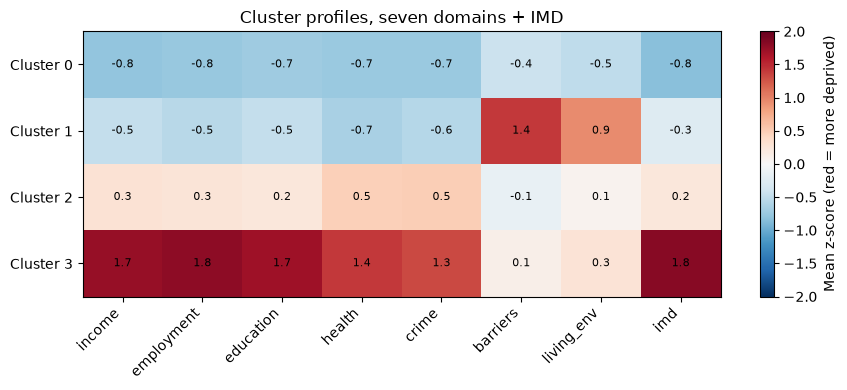

In [11]:
# Model solutions: does adding the IMD score change the K = 4 clustering?
# Run this AFTER your set-up code (it uses `d` and `domains`). It refits the
# original seven-domain clustering itself, so it does not depend on the
# earlier K-means script having been run.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

# -----------------------------------------------------------------------------
# 1. Fit both clusterings
# -----------------------------------------------------------------------------
cols_7 = domains                 # original: the seven domain scores
cols_8 = domains + ["imd"]       # new: the seven domains plus the IMD score

X7 = StandardScaler().fit_transform(d[cols_7])
X8 = StandardScaler().fit_transform(d[cols_8])

lab7 = KMeans(n_clusters=4, n_init=20, random_state=42).fit_predict(X7)
lab8 = KMeans(n_clusters=4, n_init=20, random_state=42).fit_predict(X8)

# Order the labels by mean IMD (0 = least deprived) so the two solutions are
# easy to compare. Label numbers from K-means are arbitrary.
def order_by_imd(labels):
    order = d.groupby(labels)["imd"].mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return pd.Series(labels, index=d.index).map(mapping).to_numpy()

lab7 = order_by_imd(lab7)
lab8 = order_by_imd(lab8)

print("Cluster sizes, seven domains: ", np.bincount(lab7))
print("Cluster sizes, domains + IMD: ", np.bincount(lab8))

# -----------------------------------------------------------------------------
# 2. How many assignments change? Adjusted Rand index and a cross-tab
# -----------------------------------------------------------------------------
# The ARI compares two groupings without needing the labels to match:
# 1 = identical partitions, about 0 = no more agreement than chance.
ari = adjusted_rand_score(lab7, lab8)
print(f"\nAdjusted Rand index (7 domains vs 7 domains + IMD): {ari:.3f}")

# Rows = original cluster, columns = new cluster.
cross = pd.crosstab(lab7, lab8, rownames=["original"], colnames=["with IMD"])
print("\nCross-tab of cluster membership:")
print(cross)

# Count LSOAs that changed group. The cluster numbers might not line up even
# after ordering by IMD, so match each original cluster to the new cluster it
# overlaps most (Hungarian algorithm) before counting.
rows, cols_idx = linear_sum_assignment(-cross.to_numpy())
unchanged = cross.to_numpy()[rows, cols_idx].sum()
changed = len(d) - unchanged
print(f"\nLSOAs that stay in their matched cluster: {unchanged} "
      f"({unchanged / len(d):.1%})")
print(f"LSOAs that change cluster: {changed} ({changed / len(d):.1%})")

# Row percentages show where each original cluster's members went.
print("\nWhere each original cluster ended up (row %):")
print((cross.div(cross.sum(axis=1), axis=0) * 100).round(1))

# -----------------------------------------------------------------------------
# 3. Is the new clustering "better"? Several ways to look at it
# -----------------------------------------------------------------------------
# "Better" has to be defined. Candidate measures:
#
# (a) Internal cluster quality: silhouette (higher is better), Davies-Bouldin
#     (lower is better), Calinski-Harabasz (higher is better).
#     CAUTION: these cannot be compared directly between the two runs, because
#     they are computed in different feature spaces (7-d versus 8-d). The extra
#     IMD column is highly correlated with the others, so the 8-d space has a
#     different shape. To compare fairly, score BOTH labelings in the SAME space.
#     Even then, a clustering will tend to score best in the space it was
#     fitted in, so a higher score there is not proof of a better clustering.
#
# (b) Stability: do we get the same groups from a different random start?
#
# (c) External usefulness: do the groups explain something we did not cluster
#     on (here, benefits and the minority share of residents)?
#
# (d) Interpretability: do the groups tell a story that is useful?

SAMPLE = 10000   # silhouette is slow on 33k points; same sample for all runs
def internal_scores(X, labels):
    return {
        "silhouette": silhouette_score(X, labels, sample_size=SAMPLE, random_state=0),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
    }

rows_out = {}
for space_name, X in [("7-d space", X7), ("8-d space (incl. IMD)", X8)]:
    for lab_name, labels in [("labels from 7 domains", lab7), ("labels from 7 + IMD", lab8)]:
        rows_out[(space_name, lab_name)] = internal_scores(X, labels)

scores = pd.DataFrame(rows_out).T
scores.index.names = ["scored in", "clustering"]
print("\n(a) Internal quality measures, each clustering scored in each space:")
print(scores.round(3))

# (b) Stability across random starts, for each clustering
def stability(X, seeds=(1, 2, 3, 4, 5)):
    base = KMeans(n_clusters=4, n_init=20, random_state=42).fit_predict(X)
    return [
        adjusted_rand_score(
            base, KMeans(n_clusters=4, n_init=20, random_state=s).fit_predict(X)
        )
        for s in seeds
    ]

print("\n(b) Stability (ARI against the seed-42 solution, 5 other seeds):")
print("  7 domains:    ", np.round(stability(X7), 3))
print("  7 + IMD:      ", np.round(stability(X8), 3))

# (c) How much of the variation in an outside variable do the clusters explain?
# eta-squared = between-cluster variance / total variance (like R^2 for a
# categorical predictor).
def eta_squared(values, labels):
    s = pd.Series(values, index=d.index)
    group_means = s.groupby(labels).transform("mean")
    return ((group_means - s.mean()) ** 2).sum() / ((s - s.mean()) ** 2).sum()

print("\n(c) Share of variance explained by the clusters (eta-squared):")
outside = {"benefits": d["benefits"]}
if "minority_prop" in d.columns:                 # present if the earlier script ran
    outside["minority_prop"] = d["minority_prop"]
for name, vals in outside.items():
    print(f"  {name:14s} 7 domains: {eta_squared(vals, lab7):.3f}   "
          f"7 + IMD: {eta_squared(vals, lab8):.3f}")
# Benefits is partly circular: the Income and Employment domains are built from
# benefit claims. Use it with care as an "outside" check.

# -----------------------------------------------------------------------------
# 4. Profile the new clusters (z-scores, as before)
# -----------------------------------------------------------------------------
z8 = pd.DataFrame(X8, columns=cols_8, index=d.index)
z8_profile = z8.groupby(lab8).mean()
print("\n(d) Mean z-score by cluster, domains + IMD:")
print(z8_profile.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(z8_profile, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cols_8)), cols_8, rotation=45, ha="right")
ax.set_yticks(range(4), [f"Cluster {i}" for i in range(4)])
for i in range(4):
    for j in range(len(cols_8)):
        ax.text(j, i, f"{z8_profile.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Mean z-score (red = more deprived)")
ax.set_title("Cluster profiles, seven domains + IMD")
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 5. Discussion points
# -----------------------------------------------------------------------------
# * The IMD score is itself a weighted combination of the seven domains, so
#   adding it gives no new information. It acts as an extra feature that is
#   highly correlated with Income and Employment (the two heaviest-weighted
#   domains), which effectively gives "overall deprivation" more weight in the
#   distance calculation. Groups that differ mainly on lower-weighted domains
#   (barriers, living environment) may be pulled towards the groups they
#   resemble on overall deprivation.
# * Check the cross-tab and the z-score profile to see whether that is what
#   happened here, rather than assuming it.
# * A high ARI means the extra column barely changed the grouping; a low one
#   means the result is sensitive to how the features were chosen. Neither
#   tells us which solution is "right".
# * No internal score can say which clustering is better in an absolute sense.
#   "Better" depends on what the clusters will be used for, so judge them
#   against that purpose as well as the numbers.

The two clusterings are very close, and there is no meaningful sense in which the one with IMD is “better”.

Assignments that change. The adjusted Rand index is 0.869, and 32,046 LSOAs (95.0%) stay in their matched cluster, so 1,670 (5.0%) move. The changes all happen at the boundaries between neighbouring clusters: 766 LSOAs move from original cluster 2 to cluster 0, 506 from cluster 3 to cluster 2, and 249 from cluster 1 to cluster 2. The net effect is that cluster 0 grows (12,377 to 13,110) and cluster 3 shrinks (5,899 to 5,403). The output doesn’t show why the boundary shifts in that direction. You could look at the 766 LSOAs that moved from cluster 2 to cluster 0 to find out, but I wouldn’t put an explanation in the model answer without checking.

I predicted last time that adding IMD might pull the barriers and living-environment group (cluster 1) towards the groups it resembles on overall deprivation. That mostly didn’t happen. 94.4% of cluster 1 stays intact, and its profile is almost unchanged, with barriers at +1.41 and living environment at +0.94. Its IMD z-score is -0.26, so overall it is slightly below average. The IMD column duplicates information already in the seven domains, so it moves some boundaries slightly but doesn’t remove the distinct group.

Is it better? The results for each measure:

Internal scores: each clustering scores slightly better in the space it was fitted in. In the 7-d space the original wins marginally on Davies-Bouldin (1.247 vs 1.267) and Calinski-Harabasz (16,298 vs 16,233), with silhouette tied at 0.260. In the 8-d space the new one wins marginally on all three (silhouette 0.275 vs 0.274). These differences are too small to matter, and the 8-d result mainly reflects that clustering was done in 8-d.
Stability: both are very stable. ARI against other seeds is 0.986 to 0.997 for the original and 0.991 to 0.995 with IMD.
Outside variables: eta-squared for benefits rises from 0.520 to 0.538, and for minority share from 0.071 to 0.076. The gains are small, and the benefits comparison is partly circular because income and employment are built from benefit claims.
Interpretation: the four-group story is the same.

A silhouette of about 0.26 to 0.27 means the groups are only weakly separated. That fits the earlier point that deprivation is a continuum and K-means is slicing it into segments, not finding sharply distinct clouds.

One correction to my earlier interpretation. The clusters explain only 7% of the variation in minority share, even though the cluster means rise from 11.6% to 26.8%. There is a lot of overlap within clusters, so the ethnicity pattern is a modest tendency and not a defining feature of any group. I’d say that explicitly in the model answer.

Takeaway for students. Adding IMD changes about 5% of assignments, and no metric says the result is meaningfully better or worse. “Better” depends on what the clusters are for, and adding a redundant column mostly confirms that the original features already carried the information.

I can add the cluster 1 sub-domain and local-authority check next, since that group is the interesting one.

Question 5 - Yes. Everything that uses distance was standardised with StandardScaler. In both K-means scripts, each column was converted to a z-score (mean 0, standard deviation 1) before clustering. In the regression script the scaling made the coefficients comparable, but it did not change R² or the predictions.

Why it matters for K-means. K-means assigns each LSOA to the nearest centre by Euclidean distance, so a variable with a larger numeric range contributes more to that distance and therefore has more influence on the clusters. Your own output shows how different the ranges are. Mean education scores run from about 8 to 51 across clusters, barriers from 17 to 37 and living environment from 13 to 37. Income and employment are rates, with cluster means between about 0.07 and 0.49. Without rescaling, education and barriers would dominate the clustering, and income and employment, the two most heavily weighted domains in the IMD, would hardly count. The groups would reflect the units each domain happens to be measured in, not how deprived the areas are.

Standardising puts each domain on a common footing, so each contributes roughly equally to the distance. It also made the z-score profile tables possible, because the cluster means are then directly comparable across domains.

Caveats to mention:

Equal weighting is a choice. Standardising doesn’t say the domains are equally important, only that none gets extra influence because of its units. If you wanted Income and Employment to count for more, you would weight them deliberately.
Z-scores are sensitive to skew and outliers. The domain scores are skewed, so a few extreme LSOAs stretch the scale. Alternatives such as rank transforms or min-max scaling would give somewhat different clusters.
The same issue applies to PCA and to any method that depends on distances or variances. It matters much less for ordinary linear regression predictions, which is why the regression scaling only changed the coefficients’ interpretability.



## TASK 2 - Cross Validation

As discussed in Workshop 2 - Machine Learning/AI algorithms typically require a train/test split to validate performance on unseen data. In the previous task we did not split the data. 

A graphic about cross-validation can be found on the slides. Validation on unseen data can be a good way of spotting **some** types data leakage. It does this by hiding part of the data, training on the rest, and checking the predictions against the hidden part. The usual approach assigns rows to the hidden part at random. 

1. Ask your preferred LLM: "What does it mean to say that data are *spatially autocorrelated*? Why might this matter for LSOAs?" Write down the answer in one or two sentences of your own.
2. Ask your LLM to write Python code that predicts the proportion of benefit claimants from the other domain scores using a random forest, and evaluates it with standard 5-fold cross-validation. What score does it report? 
3. Now ask your LLM to repeat this, but so that *whole local authority districts* are held out together in each fold (it may suggest `GroupKFold`). How does the score change?

**Pasted all of this into Claude in one go!**

I’ve written model_solutions_cv.py for Task 2, to run after your setup code. I’ve only checked the syntax and haven’t run it on your data, so I can’t report the scores yet.

1. Spatial autocorrelation (a model answer in your own words). Places that are close together tend to have more similar values than places that are far apart. For LSOAs this matters because neighbouring areas share housing, employers and services. A random train/test split puts near-identical neighbours on both sides, so the test data isn’t truly unseen and the score can look better than it should.

2. Random forest with standard 5-fold CV. The script predicts benefits from the seven domain scores with a RandomForestRegressor. It leaves out the IMD score because that is built from the domains. It uses KFold(n_splits=5, shuffle=True) and reports R² per fold, mean R² and mean RMSE.

3. Holding out whole districts. d doesn’t carry the district code, so the script looks it up from combined_df by row index. It then uses GroupKFold(n_splits=5) with those groups, and includes a check that no district appears in both train and test in any fold. It prints the two sets of scores side by side.

What to expect. You’d typically see the grouped score come out lower than the random one, because the random score gets credit for neighbours leaking across the split. If the two are similar, that is a finding too: it would mean the relationship between the domains and benefits is consistent across districts. The comments in the script cover this, including that grouped scores often vary more between folds because each fold holds a different mix of whole districts (cities versus rural areas, for example).

Cross-validation tests generalisation to new rows or districts, but it doesn’t remove the circularity I flagged earlier. Income and Employment are built from benefit claims, so some of the predictability is by construction either way.

Once you run it, send me the two summary tables and I’ll write the comparison for the model answer.

In [13]:
# Model solutions, Task 2: cross-validation and spatial autocorrelation
# Run this AFTER your set-up code (it uses `combined_df`, `d`, `domains`, `lad`).

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_validate

# -----------------------------------------------------------------------------
# 1. Spatial autocorrelation (answer in your own words)
# -----------------------------------------------------------------------------
# Spatial autocorrelation means that places close together tend to have more
# similar values than places far apart. For LSOAs this matters because
# neighbouring areas share housing, employers, transport and services, so they
# look alike. If rows are split into train and test at random, almost every
# test LSOA has near-identical neighbours in the training set, so the "unseen"
# data is not really unseen and the cross-validated score can be too optimistic.

# -----------------------------------------------------------------------------
# 2. Random forest with standard 5-fold cross-validation
# -----------------------------------------------------------------------------
# Predict the benefits measure from the seven domain scores. The overall IMD
# score is left out because it is itself built from the domains.
X = d[domains]
y = d["benefits"]

rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

# shuffle=True assigns rows to folds at random, which is the "usual approach".
random_cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error"}
res_random = cross_validate(rf, X, y, cv=random_cv, scoring=scoring)

print("Random 5-fold CV")
print("  R^2 per fold:", res_random["test_r2"].round(3))
print(f"  mean R^2:    {res_random['test_r2'].mean():.3f}")
print(f"  mean RMSE:   {-res_random['test_rmse'].mean():.3f}")

# -----------------------------------------------------------------------------
# 3. Hold out whole local authority districts together
# -----------------------------------------------------------------------------
# `d` does not carry the district code, but it kept the row index from
# `combined_df`, so we can look it up by index.
groups = combined_df.loc[d.index, lad]
print(f"\nNumber of local authority districts in the data: {groups.nunique()}")

# GroupKFold keeps every LSOA from the same district in the same fold, so the
# model is always tested on districts it has never seen any part of.
group_cv = GroupKFold(n_splits=5)

# Check that the folds really are separated by district.
for i, (tr, te) in enumerate(group_cv.split(X, y, groups)):
    overlap = set(groups.iloc[tr]) & set(groups.iloc[te])
    assert not overlap, f"Fold {i}: districts appear in both train and test"
print("Checked: no district appears in both train and test in any fold.")

res_group = cross_validate(rf, X, y, cv=group_cv, groups=groups, scoring=scoring)

print("\nGrouped 5-fold CV (whole districts held out)")
print("  R^2 per fold:", res_group["test_r2"].round(3))
print(f"  mean R^2:    {res_group['test_r2'].mean():.3f}")
print(f"  mean RMSE:   {-res_group['test_rmse'].mean():.3f}")

# -----------------------------------------------------------------------------
# Side-by-side summary
# -----------------------------------------------------------------------------
summary = pd.DataFrame(
    {
        "mean R^2": [res_random["test_r2"].mean(), res_group["test_r2"].mean()],
        "std R^2": [res_random["test_r2"].std(), res_group["test_r2"].std()],
        "mean RMSE": [-res_random["test_rmse"].mean(), -res_group["test_rmse"].mean()],
    },
    index=["random KFold", "GroupKFold by district"],
)
print("\n", summary.round(3))

# -----------------------------------------------------------------------------
# How to read the result
# -----------------------------------------------------------------------------
# * If the grouped score is lower than the random score, the random score was
#   flattering the model: part of what it "predicted" was neighbours in the
#   training data that look like the test LSOAs. The grouped score is the more
#   honest estimate of performance in a district the model has never seen.
# * If the two scores are similar, the relationship between the domains and
#   benefits is consistent from district to district and the model is not
#   relying on local similarity. That is a useful finding too.
# * Grouped scores often vary more from fold to fold, because each fold now
#   contains a different set of whole districts (big cities versus rural
#   districts, for example). Look at the per-fold values, not just the mean.
# * Neither score removes the circularity noted earlier: the Income and
#   Employment domains are built from benefit claims, so the high predictability
#   is partly by construction. Cross-validation checks generalisation to unseen
#   rows or districts; it does not check whether the predictors are
#   independent of the target.
# * Random-forest R^2 on the same data would not be identical to the linear
#   regression R^2 from the earlier task, because the model type differs.

Random 5-fold CV
  R^2 per fold: [0.827 0.808 0.822 0.815 0.822]
  mean R^2:    0.819
  mean RMSE:   1.172

Number of local authority districts in the data: 296
Checked: no district appears in both train and test in any fold.

Grouped 5-fold CV (whole districts held out)
  R^2 per fold: [0.78  0.837 0.784 0.786 0.779]
  mean R^2:    0.793
  mean RMSE:   1.229

                         mean R^2  std R^2  mean RMSE
random KFold               0.819    0.007      1.172
GroupKFold by district     0.793    0.022      1.229


The score falls a little when whole districts are held out: mean R² goes from 0.819 to 0.793, and mean RMSE rises from 1.172 to 1.229.

What it shows.

Random folds were slightly flattering. The drop of about 0.026 in R² (RMSE about 5% worse) is the cost of removing neighbours from the training data. That is the spatial autocorrelation effect from question 1, and it is the more honest estimate of how the model does in a district it has never seen.
The effect is small. The model still explains nearly 80% of the variation in unseen districts, so the relationship between the domain scores and benefits is largely consistent across the country. The model is mostly not relying on local similarity.
Fold-to-fold variation is larger. The standard deviation of R² rises from 0.007 to 0.022. Each grouped fold holds a different set of whole districts, so some folds are easier than others. Fold 2 scores 0.837, higher than any random fold, while the other four sit around 0.78.

Cautions for the model answer.

Don’t over-read one run. The gap (0.026) is about the same size as the grouped standard deviation (0.022), and GroupKFold assigns districts to folds in a fixed way. To check the gap holds up, repeat with different random assignments of districts to folds, for example with GroupShuffleSplit or a shuffled GroupKFold in recent scikit-learn versions.
The leakage here is mild. The high score is not mainly a neighbour effect. As noted earlier, Income and Employment are built from benefit claims, so much of the predictability is by construction, and that is untouched by either cross-validation scheme.
Random CV is not wrong, just optimistic. Which scheme is appropriate depends on the question. If the model will be used for new LSOAs within districts it has seen, random folds are closer to that use. If it will be applied to new districts, the grouped score is the right one.

I can add a short repeated-grouped-CV snippet to the script so students can see whether the gap is stable.

## Task 3 - Proxies for Ethnicity

The domain scores in the IMD do not include ethnicity. In this task we ask whether that means a model built from them is "ethnicity-blind".

1. Ask your preferred LLM to write code that clusters the LSOAs using the seven domain scores (K = 4, standardised), then shows the ethnic composition of each cluster. Do the clusters differ? Describe the pattern in a sentence or two.
2. Ask your LLM to write code that tries to *predict* the minority ethnic proportion of an LSOA using the domain scores alone. How well does it do? (Think about how you want to validate it. What did you learn in Task 2?)
3. Now remove the Income and Employment domains, and repeat step 3. Does the model still predict ethnicity? What does this tell you about removing "sensitive" features from a dataset?
4. Ask your LLM: "What is the *ecological fallacy*?" Then answer: if a cluster has a high proportion of ethnic minority residents, what can you validly say about an individual who lives there?


**Claude Output**

I’ve written model_solutions_proxies.py for Task 3, to run after your setup code. I’ve only checked the syntax and haven’t run it on your data, so the results will be the first real output.

1. Clusters and ethnic composition. It reruns the K=4 standardised clustering and shows composition two ways:

Population-weighted: adds up residents per cluster and divides, so it answers “what share of residents here are in each group?”
Average LSOA: the mean of the LSOA-level proportions, so it answers “what is a typical LSOA like?”

It also prints the spread within each cluster and draws a boxplot. From your earlier output, the cluster means rise from 11.6% to 26.8% minority share, but the clusters explained only about 7% of the variation, so I’d expect heavy overlap.

2. Predicting minority proportion. It uses a random forest on the seven domains and applies the Task 2 lesson by holding out whole districts with GroupKFold. It reports a predict-the-mean baseline (R² about zero) to beat, and a random-fold score for comparison.

3. Removing Income and Employment. The task text says “repeat step 3”, and I took that to mean step 2. The script repeats the grouped-CV prediction with only the other five domains, scores each domain on its own to show where the signal sits, and prints a summary table. The comments explain why dropping obvious proxies doesn’t make a model “ethnicity-blind”. Some plausible routes are the English proficiency indicator in the Education domain, overcrowding in Barriers, and the urban character of Living Environment. I’ve marked these as untested, so please check them against the output before presenting them as findings.

4. Ecological fallacy. The comments give a model answer. You can validly say that the cluster’s share of minority residents is higher than elsewhere. You can’t infer an individual’s ethnicity, income, employment or benefit status from where they live. From your earlier output, even the highest-share cluster has a majority White population on average, so a typical individual there is more likely to be White.

I framed part 2 as a diagnostic for the workshop. It shows how much ethnicity can be recovered from the remaining columns, not something to deploy to infer anyone’s ethnicity.

Send me the output when you’ve run it, and I’ll write the interpretation for the model answers.

Population-weighted ethnic composition by cluster (%):
   asian  black  mixed  white  other_ethnic  minority (not White)
0    6.4    1.7    2.5   88.1           1.3                  11.9
1   10.7    4.1    2.8   79.7           2.8                  20.3
2    9.6    5.5    3.3   79.2           2.3                  20.8
3   15.3    7.2    3.4   71.0           3.1                  29.0

Mean of LSOA-level proportions by cluster (%):
   asian_prop  black_prop  mixed_prop  white_prop  other_ethnic_prop  \
0         6.2         1.6         2.5        88.4                1.3   
1         9.8         3.8         2.7        81.1                2.6   
2         9.1         5.2         3.2        80.3                2.2   
3        13.9         6.8         3.3        73.2                2.9   

   minority_prop  
0           11.6  
1           18.9  
2           19.7  
3           26.8  

Spread of the minority proportion within each cluster:
     count  mean   std  min   10%   50%   90%   max
0  

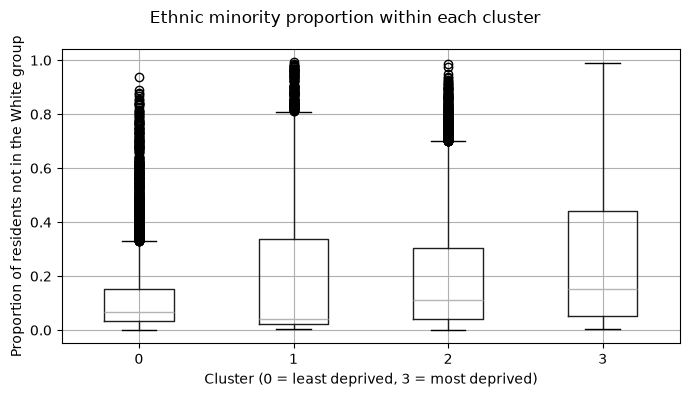


Predicting minority proportion from all seven domains
  Baseline (predict the mean): R^2 = -0.061, RMSE = 0.204
  Random forest, grouped CV:   R^2 = 0.654, RMSE = 0.115
  R^2 per fold: [0.685 0.703 0.571 0.678 0.633]


/workspaces/LISF5002M-Demos/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


  Random forest, random CV:    R^2 = 0.710, RMSE = 0.110

Without Income and Employment: features = ['education', 'health', 'crime', 'barriers', 'living_env']
  Random forest, grouped CV:   R^2 = 0.338, RMSE = 0.160
  R^2 per fold: [0.434 0.426 0.174 0.344 0.31 ]

Grouped-CV R^2 using each domain on its own:
income        0.061
employment   -0.029
crime        -0.103
health       -0.211
living_env   -0.411
barriers     -0.500
education    -0.553
dtype: float64

                              grouped-CV R^2   RMSE
baseline (mean)                      -0.061  0.204
all 7 domains                         0.654  0.115
without Income & Employment           0.338  0.160

Feature importances (reduced model, descriptive):
barriers      0.286
living_env    0.229
crime         0.216
education     0.151
health        0.118
dtype: float64


In [14]:
# Model solutions, Task 3: proxies for ethnicity
# Run this AFTER your set-up code (it uses `combined_df`, `d`, `domains`, `lad`).
#
# Note: `d` is the working frame from the set-up. It dropped the 39 LSOAs with
# a missing benefits value, which is not needed for this task but keeps the
# results consistent with the earlier tasks. `d` kept its row index from
# `combined_df`, so we use that index to pull the ethnicity columns alongside.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, KFold, cross_validate

eth = combined_df.loc[d.index]           # ethnicity columns aligned with `d`
eth_groups = ["asian", "black", "mixed", "white", "other_ethnic"]

# -----------------------------------------------------------------------------
# 1. Cluster on the seven domain scores (K = 4, standardised) and look at the
#    ethnic composition of each cluster
# -----------------------------------------------------------------------------
X_scaled = StandardScaler().fit_transform(d[domains])
raw = KMeans(n_clusters=4, n_init=20, random_state=42).fit_predict(X_scaled)

# Relabel so 0 = least deprived ... 3 = most deprived (label numbers are arbitrary).
order = d.groupby(raw)["imd"].mean().sort_values().index
mapping = {old: new for new, old in enumerate(order)}
cluster = pd.Series(raw, index=d.index).map(mapping)

# (a) Population-weighted composition: add up people, then divide. This answers
#     "what share of the residents of this cluster are in each group?"
counts = eth[eth_groups + ["total_residents"]].groupby(cluster).sum()
weighted = counts[eth_groups].div(counts["total_residents"], axis=0)
weighted["minority (not White)"] = 1 - weighted["white"]
print("Population-weighted ethnic composition by cluster (%):")
print((weighted * 100).round(1))

# (b) Average of the LSOA-level proportions: "what is a typical LSOA like?"
prop_cols = [f"{g}_prop" for g in eth_groups] + ["minority_prop"]
print("\nMean of LSOA-level proportions by cluster (%):")
print((eth.groupby(cluster)[prop_cols].mean() * 100).round(1))

# (c) The spread within each cluster matters as much as the average.
print("\nSpread of the minority proportion within each cluster:")
print(eth.groupby(cluster)["minority_prop"]
         .describe(percentiles=[0.1, 0.5, 0.9]).round(2))

# (d) Picture the spread.
fig, ax = plt.subplots(figsize=(7, 4))
eth.assign(cluster=cluster).boxplot(column="minority_prop", by="cluster", ax=ax)
ax.set(xlabel="Cluster (0 = least deprived, 3 = most deprived)",
       ylabel="Proportion of residents not in the White group",
       title="")
fig.suptitle("Ethnic minority proportion within each cluster")
fig.tight_layout()
plt.show()

# How to describe the pattern: compare the cluster averages (and say whether
# the order follows the deprivation order), then note how much the clusters
# overlap, using the spread above. Averages can differ clearly while the
# distributions still overlap heavily.

# -----------------------------------------------------------------------------
# 2. Predict the minority proportion from the domain scores alone
# -----------------------------------------------------------------------------
# Lesson from Task 2: ethnic composition is strongly geographic, so a random
# split would let a model learn "LSOAs near this one look like this". We hold
# out whole local authority districts so that the score reflects performance
# in districts the model has never seen.
y = eth["minority_prop"]
groups = eth[lad]
group_cv = GroupKFold(n_splits=5)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error"}

def cv_scores(features, model, cv=group_cv):
    res = cross_validate(model, d[features], y, cv=cv, groups=groups, scoring=scoring)
    return res["test_r2"].mean(), -res["test_rmse"].mean(), res["test_r2"]

rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)

# Baseline: always predict the training-set mean. R^2 should be about zero
# (or slightly negative), so this is the score to beat.
base_r2, base_rmse, _ = cv_scores(domains, DummyRegressor(strategy="mean"))
all_r2, all_rmse, all_folds = cv_scores(domains, rf)

print("\nPredicting minority proportion from all seven domains")
print(f"  Baseline (predict the mean): R^2 = {base_r2:.3f}, RMSE = {base_rmse:.3f}")
print(f"  Random forest, grouped CV:   R^2 = {all_r2:.3f}, RMSE = {all_rmse:.3f}")
print("  R^2 per fold:", all_folds.round(3))

# For comparison only: the same model with random folds (expect it to be a bit
# more flattering, for the Task 2 reason).
rand_cv = KFold(n_splits=5, shuffle=True, random_state=42)
r_r2, r_rmse, _ = cv_scores(domains, rf, cv=rand_cv)
print(f"  Random forest, random CV:    R^2 = {r_r2:.3f}, RMSE = {r_rmse:.3f}")

# -----------------------------------------------------------------------------
# 3. Remove Income and Employment and try again
# -----------------------------------------------------------------------------
# (The task text says "repeat step 3"; this repeats step 2, the prediction.)
reduced = [c for c in domains if c not in ("income", "employment")]
red_r2, red_rmse, red_folds = cv_scores(reduced, rf)

print(f"\nWithout Income and Employment: features = {reduced}")
print(f"  Random forest, grouped CV:   R^2 = {red_r2:.3f}, RMSE = {red_rmse:.3f}")
print("  R^2 per fold:", red_folds.round(3))

# Which of the remaining domains carry the signal? Score each one alone.
single = {dom: cv_scores([dom], rf)[0] for dom in domains}
print("\nGrouped-CV R^2 using each domain on its own:")
print(pd.Series(single).sort_values(ascending=False).round(3))

summary = pd.DataFrame(
    {"grouped-CV R^2": [base_r2, all_r2, red_r2],
     "RMSE": [base_rmse, all_rmse, red_rmse]},
    index=["baseline (mean)", "all 7 domains", "without Income & Employment"],
)
print("\n", summary.round(3))

# Descriptive only: which features does the reduced forest lean on? These are
# impurity importances from one fit on all the data, so treat them as a hint
# rather than a validated result.
rf_red = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
rf_red.fit(d[reduced], y)
print("\nFeature importances (reduced model, descriptive):")
print(pd.Series(rf_red.feature_importances_, index=reduced)
        .sort_values(ascending=False).round(3))

# What this tells us about removing "sensitive" features:
# * Deleting a sensitive variable (or the columns most obviously linked to it)
#   does not remove the information from the data. If the remaining columns
#   still predict ethnicity, they act as proxies, so a model trained on them can
#   still behave in ways that track ethnicity. "Ethnicity-blind" in the sense
#   of "the column is not in the table" is not the same as "carries no
#   information about ethnicity".
# * The proxy information can come from several places at once, which is why
#   dropping the two most obvious domains may change the score little. Some
#   plausible routes (not tested here): the Education domain includes an
#   indicator on adults' English proficiency; Barriers includes housing
#   indicators such as overcrowding; Living Environment reflects urban
#   conditions, and minority populations are concentrated in cities.
# * Checking is straightforward: try to predict the sensitive attribute from the
#   remaining features, as above, and validate on held-out places. If it can be
#   predicted well, it has not been removed.
# * This is a diagnostic. Predicting the ethnicity of individuals or small areas
#   from other data is not something to deploy.

# -----------------------------------------------------------------------------
# 4. The ecological fallacy
# -----------------------------------------------------------------------------
# The ecological fallacy is assuming that what is true of a group or area, in
# aggregate, is true of the individuals in it. Relationships and averages
# measured across areas do not necessarily hold for individuals.
#
# If a cluster has a high proportion of ethnic minority residents, you can
# validly say something about the cluster or the areas in it: for example, that
# the share of residents who are not White is higher than in other clusters.
# At most, for a randomly chosen resident, that share is the base-rate chance
# that they belong to a minority group, which is a statement about a
# population, not knowledge about that person. You cannot validly infer that
# an individual living there is from a minority group (look at the cluster
# averages above: even in the cluster with the highest average share, most
# residents are White), or anything about their income, employment, health or
# benefit claims. The area-level scores describe the neighbourhood, and
# individual residents can differ greatly from it.

Here is how I’d read the part 1 output for the model answer.

Do the clusters differ? Yes, on average. The population-weighted minority share is 11.9% in cluster 0, 20.3% in cluster 1, 20.8% in cluster 2 and 29.0% in cluster 3. So it rises with deprivation, and the most deprived cluster has roughly 2.4 times the share of the least deprived. Clusters 1 and 2 are almost the same overall, although they have very different deprivation profiles.

A draft model answer: “Ethnic minority share is lowest in the least deprived cluster (about 12%) and highest in the most deprived (about 29%), with clusters 1 and 2 in between at about 20%. The clusters differ on average, but the distributions within each overlap heavily.”

Points the output supports:

The averages hide a lot of spread. In every cluster, LSOAs range from about 0% to 94-99% minority. In cluster 3 the 10th percentile is 3% and the 90th is 71%.
The distributions are skewed. The medians are far below the means in clusters 1 to 3. Cluster 3 has a mean of 27% but a median of 15%, and cluster 1 has a mean of 19% but a median of 4%. Most LSOAs have low minority shares and a smaller number have very high ones.
Cluster 1 is notable. Its median (4%) is lower than cluster 0’s (7%), yet its mean is higher and its 90th percentile reaches 60%. That is consistent with a mix of very low-minority areas and a subset of high-minority areas, which fits the earlier idea that this barriers-and-environment group combines rural and urban places. It is consistent with that idea, not proof, and the sub-domain or district check would settle it.
The composition of the minority share differs, not just its size. Asian residents are the largest minority group in every cluster. Cluster 2 has a higher Black share than cluster 1 (5.5% against 4.1%) but a lower Asian share (9.6% against 10.7%), so the two look alike on “minority” overall while being composed differently. A single minority proportion hides this.
The weighted figures are slightly higher than the LSOA averages (for example 29.0% against 26.8% in cluster 3). That means LSOAs with higher minority shares tend to have more residents.

Link to part 4. This output supports the ecological fallacy answer directly. Even in the cluster with the highest average share, about 71% of residents are White, so a typical resident there is White, and a cluster label says little about any one person.

You haven’t pasted the output for parts 2 and 3 yet. Send that when you have it and I’ll write up how well the domains predict minority share and what happens when Income and Employment are removed.